# Motivation 5: driving range and operating time vs SOH

Full battery (SOC 100 % -> 5 % reserve) discharged at a constant load (2RC ECM constant-power discharge, so capacity fade and the growing internal-resistance losses are both included). Medium complexity.
(a) mechanical subsystem: driving range vs speed at a fixed CPU frequency (1.42 GHz);
(b) computational subsystem: operating time vs CPU frequency at a fixed speed (3 m/s).
Output: `figures/pdf/motivation_5.pdf`.

In [5]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import envs  # noqa: F401  (sys.path for battery_model)
from envs.robot_env import (ECMBattery, BatteryLimitError, ECMParams, motor_power, non_motor_power, CPU_FREQ_GHZ,
                            throughput_freq_required, quantize_freq)
from envs.test_env import EVAL_CONFIG, make_robot

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 15, 'axes.titlesize': 15, 'axes.labelsize': 15,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 15,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

## Settings

In [6]:
ROBOT = make_robot(EVAL_CONFIG)
ECM = ECMParams.default(ROBOT)
SOC0 = 1.0                                   # full charge, discharged down to the SOC reserve
RESERVE = ROBOT.soc_reserve                  # 5 %
SOHS = [1.00, 0.90, 0.80]                    # state of health
C = 2.0                                      # medium workload complexity
F_FIX = 1.42                                 # (a) fixed CPU frequency [GHz]
V_FIX = 3.0                                  # (b) fixed speed [m/s]
SPEEDS = np.round(np.arange(1.0, ROBOT.v_max + 1e-9, 0.1), 2)
DT = 5.0                                     # discharge simulation step [s]
print(f'C = {C:g}, (a) f = {F_FIX} GHz, (b) v = {V_FIX} m/s, SOC {SOC0:g} -> {RESERVE:g}')

C = 2, (a) f = 1.42 GHz, (b) v = 3.0 m/s, SOC 1 -> 0.05


## Constant-load discharge

In [7]:
def runtime_h(p_load, soh):
    """Hours a full battery sustains the constant load p_load [W] until the SOC reserve
    (2RC ECM constant-power discharge: OCV, R0 and RC losses all depend on SOC and SOH)."""
    b = ECMBattery(ECM, ROBOT, soc_init=SOC0, soh_init=soh)
    t = 0.0
    try:
        while b.soc > RESERVE:
            b.step(p_load, dt=DT)
            t += DT
    except BatteryLimitError:
        pass
    return t / 3600.0


P_LOAD_V = np.array([motor_power(v, 0.0, ROBOT) + non_motor_power(v, F_FIX, C, ROBOT) for v in SPEEDS])
P_LOAD_F = np.array([motor_power(V_FIX, 0.0, ROBOT) + non_motor_power(V_FIX, f, C, ROBOT)
                     for f in CPU_FREQ_GHZ])
RANGE_KM = {h: np.array([3.6 * v * runtime_h(p, h) for v, p in zip(SPEEDS, P_LOAD_V)]) for h in SOHS}
TIME_H = {h: np.array([runtime_h(p, h) for p in P_LOAD_F]) for h in SOHS}
for h in SOHS:
    print(f'SOH {h:.2f}: range at 1 / 3 / 5 m/s = {RANGE_KM[h][0]:.1f} / {RANGE_KM[h][20]:.1f} / '
          f'{RANGE_KM[h][-1]:.1f} km, time at {CPU_FREQ_GHZ[0]:.2f} / {CPU_FREQ_GHZ[-1]:.2f} GHz = '
          f'{TIME_H[h][0]:.2f} / {TIME_H[h][-1]:.2f} h')

SOH 1.00: range at 1 / 3 / 5 m/s = 23.7 / 45.4 / 35.1 km, time at 0.50 / 2.04 GHz = 4.34 / 3.95 h
SOH 0.90: range at 1 / 3 / 5 m/s = 21.1 / 40.5 / 31.1 km, time at 0.50 / 2.04 GHz = 3.87 / 3.52 h
SOH 0.80: range at 1 / 3 / 5 m/s = 18.7 / 35.7 / 27.3 km, time at 0.50 / 2.04 GHz = 3.41 / 3.11 h


## Figure

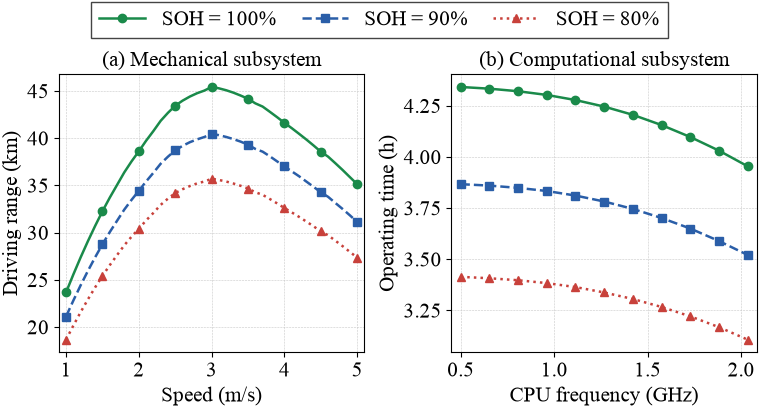

In [ ]:
# SOH: colour + line style + marker (distinguishable in greyscale)
SOH_STYLE = {1.00: dict(color='#1a8a4a', ls='-', marker='o'),
             0.90: dict(color='#2a5ea8', ls='--', marker='s'),
             0.80: dict(color='#c8413b', ls=':', marker='^')}
LW, MS = 1.8, 6
MARK_V = np.isclose(np.mod(SPEEDS + 1e-9, 0.5), 0.0, atol=1e-6)     # (a) markers every 0.5 m/s

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

ax = axes[0]
for h in SOHS:
    ax.plot(SPEEDS, RANGE_KM[h], lw=LW, ms=MS, markevery=list(np.flatnonzero(MARK_V)), **SOH_STYLE[h])
ax.set_xlabel('Speed (m/s)')
ax.set_ylabel('Driving range (km)')
ax.set_title('(a) Mechanical subsystem')
ax.set_xlim(SPEEDS[0] - 0.1, SPEEDS[-1] + 0.1)
ax.set_xticks([1, 2, 3, 4, 5])

ax = axes[1]
for h in SOHS:
    ax.plot(CPU_FREQ_GHZ, TIME_H[h], lw=LW, ms=MS, **SOH_STYLE[h])
ax.set_xlabel('CPU frequency (GHz)')
ax.set_ylabel('Operating time (h)')
ax.set_title('(b) Computational subsystem')
ax.set_xlim(CPU_FREQ_GHZ[0] - 0.05, CPU_FREQ_GHZ[-1] + 0.05)
ax.set_xticks([0.5, 1.0, 1.5, 2.0])

handles = [Line2D([], [], lw=LW, ms=MS, label=f'SOH = {100 * h:.0f}%', **SOH_STYLE[h]) for h in SOHS]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.97), ncol=3, frameon=True,
           fancybox=False, edgecolor='#444444', framealpha=1.0, handlelength=2.2, columnspacing=1.2,
           borderpad=0.4)
fig.tight_layout(w_pad=1.2)
fig.savefig(OUT / 'motivation_5.pdf')
plt.show()